In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Project data folder
DATA_PATH = r"F:\DATA ANALYST\Project 3\Marketing_Campaign_Analytics_Dataset\data\cleaned"

# Load all 5 final datasets
campaigns = pd.read_csv(os.path.join(DATA_PATH, "campaigns_final.csv"))
daily_performance = pd.read_csv(os.path.join(DATA_PATH, "daily_performance_final.csv"))
leads = pd.read_csv(os.path.join(DATA_PATH, "leads_final.csv"))
conversions = pd.read_csv(os.path.join(DATA_PATH, "conversions_final.csv"))
marketing_channels = pd.read_csv(os.path.join(DATA_PATH, "marketing_channels_final.csv"))

print("ALL DATASETS LOADED SUCCESSFULLY!")
print("-" * 50)

datasets = {
    "Campaigns": campaigns,
    "Daily Performance": daily_performance,
    "Leads": leads,
    "Conversions": conversions,
    "Marketing Channels": marketing_channels
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows | {df.shape[1]} columns")


ALL DATASETS LOADED SUCCESSFULLY!
--------------------------------------------------
Campaigns: 89 rows | 10 columns
Daily Performance: 4183 rows | 8 columns
Leads: 3000 rows | 8 columns
Conversions: 1200 rows | 6 columns
Marketing Channels: 6 rows | 5 columns


In [2]:

print("CAMPAIGNS DATA AUDIT")
print("-" * 45)

print("Total rows:", len(campaigns))
print("Unique Campaign IDs:", campaigns["campaign_id"].nunique())
print("Duplicate Campaign IDs:", campaigns["campaign_id"].duplicated().sum())
print("Missing values:")
print(campaigns.isnull().sum())

display(campaigns.head(10))


CAMPAIGNS DATA AUDIT
---------------------------------------------
Total rows: 89
Unique Campaign IDs: 61
Duplicate Campaign IDs: 28
Missing values:
campaign_id            0
campaign_name          0
channel_id             0
objective              0
product_category       0
target_city            0
region                 0
start_date            29
end_date              29
planned_budget_inr    29
dtype: int64


,campaign_id,campaign_name,channel_id,objective,product_category,target_city,region,start_date,end_date,planned_budget_inr
0,CAM001,Summer Style Fest 01,CH01,Sales,Electronics,Pune,West,2025-10-01,2025-12-31,324000.0
1,CAM002,Monsoon Essentials 02,CH02,Sales,Fashion,Pune,West,2024-03-05,2024-08-01,276000.0
2,CAM003,Independence Day Sale 03,CH03,Lead Generation,Beauty,Jaipur,North,2024-12-15,2025-05-01,141000.0
3,CAM004,Festive Preview 04,CH04,Sales,Beauty,Pune,West,2024-03-20,2024-05-12,267000.0
4,CAM005,Diwali Dhamaka 05,CH05,Awareness,Home & Kitchen,Jaipur,North,2025-05-09,2025-07-25,476000.0
5,CAM006,Winter Warmth 06,CH06,Lead Generation,Electronics,Chennai,South,2025-02-26,2025-04-21,153000.0
6,CAM007,New Arrivals Launch 07,CH01,Traffic,Lifestyle,Delhi,North,2025-03-21,2025-06-06,533000.0
7,CAM008,Weekend Flash Sale 08,CH02,Lead Generation,Home & Kitchen,Delhi,North,2024-03-03,2024-06-18,308000.0
8,CAM009,Clearance Carnival 09,CH03,Lead Generation,Fashion,Jaipur,North,2024-09-27,2024-11-15,532000.0
9,CAM010,Premium Collection 10,CH04,Sales,Home & Kitchen,Jaipur,North,2024-09-18,2024-11-15,588000.0


In [3]:

print("DUPLICATE CAMPAIGN RECORDS")
print("-" * 50)

duplicates = campaigns[
    campaigns.duplicated(subset=["campaign_id"], keep=False)
].sort_values("campaign_id")

display(duplicates)

print("\nRECORDS WITH MISSING DATES OR BUDGET")
print("-" * 50)

incomplete = campaigns[
    campaigns[["start_date", "end_date", "planned_budget_inr"]]
    .isnull().any(axis=1)
]

display(incomplete)

print("\nUNIQUE CAMPAIGN IDs")
print(sorted(campaigns["campaign_id"].unique()))


DUPLICATE CAMPAIGN RECORDS
--------------------------------------------------


,campaign_id,campaign_name,channel_id,objective,product_category,target_city,region,start_date,end_date,planned_budget_inr
60,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
86,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
85,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
84,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
83,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
82,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
81,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
80,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
79,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
78,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN



RECORDS WITH MISSING DATES OR BUDGET
--------------------------------------------------


,campaign_id,campaign_name,channel_id,objective,product_category,target_city,region,start_date,end_date,planned_budget_inr
60,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
61,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
62,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
63,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
64,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
65,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
66,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
67,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
68,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN
69,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN



UNIQUE CAMPAIGN IDs
['CAM001', 'CAM002', 'CAM003', 'CAM004', 'CAM005', 'CAM006', 'CAM007', 'CAM008', 'CAM009', 'CAM010', 'CAM011', 'CAM012', 'CAM013', 'CAM014', 'CAM015', 'CAM016', 'CAM017', 'CAM018', 'CAM019', 'CAM020', 'CAM021', 'CAM022', 'CAM023', 'CAM024', 'CAM025', 'CAM026', 'CAM027', 'CAM028', 'CAM029', 'CAM030', 'CAM031', 'CAM032', 'CAM033', 'CAM034', 'CAM035', 'CAM036', 'CAM037', 'CAM038', 'CAM039', 'CAM040', 'CAM041', 'CAM042', 'CAM043', 'CAM044', 'CAM045', 'CAM046', 'CAM047', 'CAM048', 'CAM049', 'CAM050', 'CAM051', 'CAM052', 'CAM053', 'CAM054', 'CAM055', 'CAM056', 'CAM057', 'CAM058', 'CAM059', 'CAM060', 'Unknown']


In [4]:

# Separate valid and invalid campaign records
campaigns_valid = campaigns[
    campaigns["campaign_id"].astype(str).str.strip().str.upper() != "UNKNOWN"
].copy()

print("CAMPAIGN DATA VALIDATION")
print("-" * 40)
print("Original rows:", len(campaigns))
print("Valid rows:", len(campaigns_valid))
print("Unique Campaign IDs:", campaigns_valid["campaign_id"].nunique())
print("Remaining missing values:")
print(campaigns_valid.isnull().sum())

print("\nDuplicate Campaign IDs:")
print(campaigns_valid["campaign_id"].duplicated().sum())


CAMPAIGN DATA VALIDATION
----------------------------------------
Original rows: 89
Valid rows: 60
Unique Campaign IDs: 60
Remaining missing values:
campaign_id           0
campaign_name         0
channel_id            0
objective             0
product_category      0
target_city           0
region                0
start_date            0
end_date              0
planned_budget_inr    0
dtype: int64

Duplicate Campaign IDs:
0


In [5]:

print("CAMPAIGN DATA TYPES")
print("-" * 40)
print(campaigns_valid.dtypes)

# Convert date columns
campaigns_valid["start_date"] = pd.to_datetime(
    campaigns_valid["start_date"], errors="coerce"
)

campaigns_valid["end_date"] = pd.to_datetime(
    campaigns_valid["end_date"], errors="coerce"
)

print("\nDATE VALIDATION")
print("-" * 40)
print("Invalid start dates:", campaigns_valid["start_date"].isna().sum())
print("Invalid end dates:", campaigns_valid["end_date"].isna().sum())

print("\nCAMPAIGN BUDGET SUMMARY")
display(campaigns_valid["planned_budget_inr"].describe())


CAMPAIGN DATA TYPES
----------------------------------------
campaign_id            object
campaign_name          object
channel_id             object
objective              object
product_category       object
target_city            object
region                 object
start_date             object
end_date               object
planned_budget_inr    float64
dtype: object

DATE VALIDATION
----------------------------------------
Invalid start dates: 0
Invalid end dates: 0

CAMPAIGN BUDGET SUMMARY


count        60.000000
mean     382150.000000
std      184824.224786
min       81000.000000
25%      210500.000000
50%      421000.000000
75%      540000.000000
max      636000.000000
Name: planned_budget_inr, dtype: float64

In [6]:

# Use validated campaigns data
datasets = {
    "Campaigns": campaigns_valid,
    "Daily Performance": daily_performance,
    "Leads": leads,
    "Conversions": conversions,
    "Marketing Channels": marketing_channels
}

primary_keys = {
    "Campaigns": "campaign_id",
    "Daily Performance": "performance_id",
    "Leads": "lead_id",
    "Conversions": "conversion_id",
    "Marketing Channels": "channel_id"
}

print("COMPLETE DATA QUALITY AUDIT")
print("=" * 65)

for name, df in datasets.items():
    key = primary_keys[name]

    print(f"\n{name}")
    print("-" * 45)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate primary keys:", df[key].duplicated().sum())
    print("Unique primary keys:", df[key].nunique())


COMPLETE DATA QUALITY AUDIT

Campaigns
---------------------------------------------
Rows: 60
Columns: 10
Missing values: 0
Duplicate primary keys: 0
Unique primary keys: 60

Daily Performance
---------------------------------------------
Rows: 4183
Columns: 8
Missing values: 0
Duplicate primary keys: 0
Unique primary keys: 4183

Leads
---------------------------------------------
Rows: 3000
Columns: 8
Missing values: 0
Duplicate primary keys: 0
Unique primary keys: 3000

Conversions
---------------------------------------------
Rows: 1200
Columns: 6
Missing values: 0
Duplicate primary keys: 0
Unique primary keys: 1200

Marketing Channels
---------------------------------------------
Rows: 6
Columns: 5
Missing values: 0
Duplicate primary keys: 0
Unique primary keys: 6


In [7]:

print("FOREIGN KEY RELATIONSHIP VALIDATION")
print("=" * 55)

checks = {
    "Campaigns → Marketing Channels":
        (campaigns_valid, "channel_id",
         marketing_channels, "channel_id"),

    "Daily Performance → Campaigns":
        (daily_performance, "campaign_id",
         campaigns_valid, "campaign_id"),

    "Leads → Campaigns":
        (leads, "campaign_id",
         campaigns_valid, "campaign_id"),

    "Conversions → Leads":
        (conversions, "lead_id",
         leads, "lead_id")
}

for name, (child, child_col, parent, parent_col) in checks.items():
    unmatched = ~child[child_col].isin(parent[parent_col])
    
    print(f"\n{name}")
    print("Total records:", len(child))
    print("Unmatched records:", unmatched.sum())
    print("Status:", "PASS" if unmatched.sum() == 0 else "CHECK")


FOREIGN KEY RELATIONSHIP VALIDATION

Campaigns → Marketing Channels
Total records: 60
Unmatched records: 0
Status: PASS

Daily Performance → Campaigns
Total records: 4183
Unmatched records: 0
Status: PASS

Leads → Campaigns
Total records: 3000
Unmatched records: 0
Status: PASS

Conversions → Leads
Total records: 1200
Unmatched records: 0
Status: PASS


In [8]:

date_columns = {
    "Daily Performance": (daily_performance, "performance_date"),
    "Leads": (leads, "lead_date"),
    "Conversions": (conversions, "conversion_date")
}

print("DATE COLUMN VALIDATION")
print("=" * 50)

for name, (df, col) in date_columns.items():
    df[col] = pd.to_datetime(df[col], errors="coerce")

    print(f"\n{name}")
    print("Date column:", col)
    print("Invalid dates:", df[col].isna().sum())
    print("Earliest date:", df[col].min())
    print("Latest date:", df[col].max())
    print("Data type:", df[col].dtype)


DATE COLUMN VALIDATION

Daily Performance
Date column: performance_date
Invalid dates: 0
Earliest date: 2024-01-07 00:00:00
Latest date: 2025-12-31 00:00:00
Data type: datetime64[ns]

Leads
Date column: lead_date
Invalid dates: 0
Earliest date: 2024-01-07 00:00:00
Latest date: 2025-12-31 00:00:00
Data type: datetime64[ns]

Conversions
Date column: conversion_date
Invalid dates: 0
Earliest date: 2024-01-28 00:00:00
Latest date: 2026-01-08 00:00:00
Data type: datetime64[ns]


In [9]:

# Merge campaign dates into performance and leads
performance_check = daily_performance.merge(
    campaigns_valid[["campaign_id", "start_date", "end_date"]],
    on="campaign_id",
    how="left"
)

leads_check = leads.merge(
    campaigns_valid[["campaign_id", "start_date", "end_date"]],
    on="campaign_id",
    how="left"
)

# Check date boundaries
performance_outside = (
    (performance_check["performance_date"] < performance_check["start_date"]) |
    (performance_check["performance_date"] > performance_check["end_date"])
)

leads_outside = (
    (leads_check["lead_date"] < leads_check["start_date"]) |
    (leads_check["lead_date"] > leads_check["end_date"])
)

conversion_check = conversions.merge(
    leads[["lead_id", "lead_date"]],
    on="lead_id",
    how="left"
)

conversion_before_lead = (
    conversion_check["conversion_date"] < conversion_check["lead_date"]
)

print("BUSINESS DATE CONSISTENCY")
print("-" * 45)
print("Performance outside campaign period:", performance_outside.sum())
print("Leads outside campaign period:", leads_outside.sum())
print("Conversions before lead date:", conversion_before_lead.sum())


BUSINESS DATE CONSISTENCY
---------------------------------------------
Performance outside campaign period: 0
Leads outside campaign period: 0
Conversions before lead date: 0


In [10]:

print("NUMERICAL DATA ANALYSIS")
print("=" * 60)

print("\n1. DAILY PERFORMANCE")
display(daily_performance[
    ["impressions", "clicks", "ad_spend_inr"]
].describe().round(2))

print("\n2. CONVERSION ANALYSIS")
display(conversions[
    ["order_value_inr"]
].describe().round(2))

print("\n3. CAMPAIGN BUDGET ANALYSIS")
display(campaigns_valid[
    ["planned_budget_inr"]
].describe().round(2))

print("\n4. CUSTOMER AGE GROUP DISTRIBUTION")
display(leads["customer_age_group"].value_counts())

print("\n5. CUSTOMER SEGMENT DISTRIBUTION")
display(leads["customer_segment"].value_counts())


NUMERICAL DATA ANALYSIS

1. DAILY PERFORMANCE


,impressions,clicks,ad_spend_inr
count,4183.00,4183.00,4183.00
mean,29478.38,620.67,1381.11
std,30884.06,335.63,602.86
min,1335.00,85.00,316.99
25%,11221.00,356.00,864.41
50%,19951.00,568.00,1374.58
75%,34945.50,822.00,1860.27
max,323883.00,2088.00,2876.30



2. CONVERSION ANALYSIS


,order_value_inr
count,1200.00
mean,5995.41
std,5046.49
min,541.47
25%,2615.25
50%,4284.54
75%,7669.43
max,35878.35



3. CAMPAIGN BUDGET ANALYSIS


,planned_budget_inr
count,60.00
mean,382150.00
std,184824.22
min,81000.00
25%,210500.00
50%,421000.00
75%,540000.00
max,636000.00



4. CUSTOMER AGE GROUP DISTRIBUTION


customer_age_group
25-34    1011
18-24     654
35-44     654
45-54     467
55+       214
Name: count, dtype: int64


5. CUSTOMER SEGMENT DISTRIBUTION


customer_segment
Young Professionals    943
Value Seekers          886
Families               770
Premium Shoppers       401
Name: count, dtype: int64

In [11]:

print("CAMPAIGN OBJECTIVE DISTRIBUTION")
print("=" * 50)

display(campaigns_valid["objective"].value_counts())

print("\nMARKETING CHANNEL DISTRIBUTION")
print("=" * 50)

channel_analysis = campaigns_valid.merge(
    marketing_channels,
    on="channel_id",
    how="left"
)

display(
    channel_analysis["channel_name"].value_counts()
)

print("\nREGION-WISE CAMPAIGN DISTRIBUTION")
print("=" * 50)

display(campaigns_valid["region"].value_counts())

print("\nPRODUCT CATEGORY DISTRIBUTION")
print("=" * 50)

display(campaigns_valid["product_category"].value_counts())


CAMPAIGN OBJECTIVE DISTRIBUTION


objective
Lead Generation    24
Sales              17
Awareness          11
Traffic             8
Name: count, dtype: int64


MARKETING CHANNEL DISTRIBUTION


channel_name
INSTAGRAM ADS      10
Facebook Ads       10
Instagram Ads      10
Email Marketing    10
Display Ads        10
 google ads        10
Name: count, dtype: int64


REGION-WISE CAMPAIGN DISTRIBUTION


region
West     30
North    14
South    13
East      3
Name: count, dtype: int64


PRODUCT CATEGORY DISTRIBUTION


product_category
Beauty            15
Electronics       12
Home & Kitchen    12
Fashion           11
Lifestyle         10
Name: count, dtype: int64

In [12]:

print("CHANNEL ID AND NAME MAPPING")
print("=" * 50)

display(
    marketing_channels[
        ["channel_id", "channel_name"]
    ].sort_values("channel_id")
)


CHANNEL ID AND NAME MAPPING


,channel_id,channel_name
0,CH01,INSTAGRAM ADS
1,CH02,Facebook Ads
2,CH03,Instagram Ads
3,CH04,Email Marketing
4,CH05,Display Ads
5,CH06,google ads


In [13]:

channel_performance = (
    daily_performance
    .merge(
        campaigns_valid[["campaign_id", "channel_id"]],
        on="campaign_id",
        how="left"
    )
    .merge(
        marketing_channels[["channel_id", "channel_name"]],
        on="channel_id",
        how="left"
    )
    .groupby(["channel_id", "channel_name"], as_index=False)
    .agg({
        "impressions": "sum",
        "clicks": "sum",
        "ad_spend_inr": "sum"
    })
)

channel_performance["CTR (%)"] = (
    channel_performance["clicks"] /
    channel_performance["impressions"] * 100
)

channel_performance["CPC (INR)"] = (
    channel_performance["ad_spend_inr"] /
    channel_performance["clicks"]
)

display(
    channel_performance.sort_values(
        "CTR (%)", ascending=False
    ).round(2)
)


,channel_id,channel_name,impressions,clicks,ad_spend_inr,CTR (%),CPC (INR)
3,CH04,Email Marketing,8384394,581822,944822.24,6.94,1.62
0,CH01,INSTAGRAM ADS,10914501,365292,1014761.15,3.35,2.78
2,CH03,Instagram Ads,14432909,363088,916483.60,2.52,2.52
1,CH02,Facebook Ads,22803195,482827,1060140.53,2.12,2.20
5,CH06,google ads,18024510,313412,1001245.21,1.74,3.19
4,CH05,Display Ads,48748568,489828,839726.80,1.00,1.71


In [14]:

# Connect conversions -> leads -> campaigns -> channels

revenue_analysis = (
    conversions
    .merge(
        leads[["lead_id", "campaign_id"]],
        on="lead_id",
        how="left"
    )
    .merge(
        campaigns_valid[["campaign_id", "channel_id"]],
        on="campaign_id",
        how="left"
    )
    .merge(
        marketing_channels[["channel_id", "channel_name"]],
        on="channel_id",
        how="left"
    )
)

channel_revenue = (
    revenue_analysis
    .groupby(["channel_id", "channel_name"], as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum")
    )
)

channel_revenue["AOV"] = (
    channel_revenue["total_revenue"] /
    channel_revenue["total_conversions"]
)

display(
    channel_revenue.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,channel_id,channel_name,total_conversions,total_revenue,AOV
1,CH02,Facebook Ads,216,1590408.73,7363.00
3,CH04,Email Marketing,268,1340294.05,5001.10
4,CH05,Display Ads,258,1317178.56,5105.34
0,CH01,INSTAGRAM ADS,152,1129391.65,7430.21
2,CH03,Instagram Ads,167,976042.99,5844.57
5,CH06,google ads,139,841176.32,6051.63


In [15]:

total_revenue = conversions["order_value_inr"].sum()
total_ad_spend = daily_performance["ad_spend_inr"].sum()
total_leads = leads["lead_id"].nunique()
total_conversions = conversions["conversion_id"].nunique()
total_impressions = daily_performance["impressions"].sum()
total_clicks = daily_performance["clicks"].sum()

overall_ctr = (total_clicks / total_impressions) * 100
conversion_rate = (total_conversions / total_leads) * 100
overall_cpc = total_ad_spend / total_clicks
average_order_value = total_revenue / total_conversions

ad_spend_roi = (
    (total_revenue - total_ad_spend) / total_ad_spend
) * 100

print("OVERALL MARKETING PERFORMANCE")
print("=" * 50)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Ad Spend: ₹{total_ad_spend:,.2f}")
print(f"Total Leads: {total_leads:,}")
print(f"Total Conversions: {total_conversions:,}")
print(f"Total Impressions: {total_impressions:,}")
print(f"Total Clicks: {total_clicks:,}")
print(f"Overall CTR: {overall_ctr:.2f}%")
print(f"Lead-to-Conversion Rate: {conversion_rate:.2f}%")
print(f"Average CPC: ₹{overall_cpc:.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Ad-Spend ROI: {ad_spend_roi:.2f}%")


OVERALL MARKETING PERFORMANCE
Total Revenue: ₹7,194,492.30
Total Ad Spend: ₹5,777,179.53
Total Leads: 3,000
Total Conversions: 1,200
Total Impressions: 123,308,077
Total Clicks: 2,596,269
Overall CTR: 2.11%
Lead-to-Conversion Rate: 40.00%
Average CPC: ₹2.23
Average Order Value: ₹5,995.41
Ad-Spend ROI: 24.53%


In [16]:

print("AD SPEND VALIDATION")
print("=" * 45)

print("Daily Performance Total:")
print(round(daily_performance["ad_spend_inr"].sum(), 2))

print("\nChannel-wise Total:")
print(round(channel_performance["ad_spend_inr"].sum(), 2))

print("\nDifference:")
print(round(
    daily_performance["ad_spend_inr"].sum()
    - channel_performance["ad_spend_inr"].sum(), 2
))

print("\nCampaign-wise Spend:")
campaign_spend = (
    daily_performance.groupby("campaign_id")["ad_spend_inr"]
    .sum()
    .reset_index()
)

print("Campaigns with performance:", len(campaign_spend))
print("Total campaign spend:", round(campaign_spend["ad_spend_inr"].sum(), 2))


AD SPEND VALIDATION
Daily Performance Total:
5777179.53

Channel-wise Total:
5777179.53

Difference:
0.0

Campaign-wise Spend:
Campaigns with performance: 60
Total campaign spend: 5777179.53


In [17]:

import os
import pandas as pd

CLEAN_PATH = r"F:\DATA ANALYST\Project 3\Marketing_Campaign_Analytics_Dataset\data\cleaned"
RAW_PATH = r"F:\DATA ANALYST\Project 3\Marketing_Campaign_Analytics_Dataset\data\raw"

files_to_check = {
    "Raw": os.path.join(RAW_PATH, "daily_performance.csv"),
    "Cleaned": os.path.join(CLEAN_PATH, "daily_performance_cleaned.csv"),
    "Final": os.path.join(CLEAN_PATH, "daily_performance_final.csv")
}

print("DAILY PERFORMANCE FILE COMPARISON")
print("=" * 55)

for version, path in files_to_check.items():
    df = pd.read_csv(path)
    print(f"\n{version}")
    print("Rows:", len(df))
    print("Total Ad Spend:", round(df["ad_spend_inr"].sum(), 2))


DAILY PERFORMANCE FILE COMPARISON

Raw
Rows: 4195
Total Ad Spend: 5793126.9

Cleaned
Rows: 4183
Total Ad Spend: 5777179.53

Final
Rows: 4183
Total Ad Spend: 5777179.53


In [18]:

raw_df = pd.read_csv(files_to_check["Raw"])
final_df = pd.read_csv(files_to_check["Final"])

removed_records = raw_df[
    ~raw_df["performance_id"].isin(final_df["performance_id"])
].copy()

print("REMOVED RECORDS AUDIT")
print("=" * 50)

print("Removed rows:", len(removed_records))
print("Removed Ad Spend:",
      round(removed_records["ad_spend_inr"].sum(), 2))

print("\nMissing values in removed records:")
print(removed_records.isnull().sum())

print("\nRemoved records:")
display(removed_records)


REMOVED RECORDS AUDIT
Removed rows: 0
Removed Ad Spend: 0.0

Missing values in removed records:
performance_id         0
campaign_id            0
performance_date       0
impressions            0
clicks                 0
ad_spend_inr           0
device                 0
region                 0
Unnamed: 8             0
Duplicate check        0
Click validation       0
Spend validation       0
Unnamed: 12            0
Data Quality Check     0
Result                 0
Unnamed: 15            0
KPI                    0
Value                  0
dtype: int64

Removed records:


,performance_id,campaign_id,performance_date,impressions,clicks,ad_spend_inr,device,region,Unnamed: 8,Duplicate check,Click validation,Spend validation,Unnamed: 12,Data Quality Check,Result,Unnamed: 15,KPI,Value


In [19]:

print("RAW DATA DUPLICATE AUDIT")
print("=" * 55)

print("Raw total rows:", len(raw_df))
print("Unique performance IDs:", raw_df["performance_id"].nunique())
print("Duplicate performance IDs:",
      raw_df["performance_id"].duplicated().sum())

raw_duplicates = raw_df[
    raw_df.duplicated(subset=["performance_id"], keep=False)
].sort_values("performance_id")

print("\nDuplicate records:")
display(raw_duplicates)

print("\nDuplicate record count:",
      len(raw_duplicates))

print("Duplicate group count:",
      raw_duplicates["performance_id"].nunique())

print("Raw columns:")
print(raw_df.columns.tolist())


RAW DATA DUPLICATE AUDIT
Raw total rows: 4195
Unique performance IDs: 4183
Duplicate performance IDs: 12

Duplicate records:


,performance_id,campaign_id,performance_date,impressions,clicks,ad_spend_inr,device,region,Unnamed: 8,Duplicate check,Click validation,Spend validation,Unnamed: 12,Data Quality Check,Result,Unnamed: 15,KPI,Value
96,PERF000097,CAM002,2024-04-18,23271,416,1020.01,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
4186,PERF000097,CAM002,2024-04-18,23271,416,1020.01,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
109,PERF000110,CAM002,2024-05-06,10263,254,752.16,Desktop,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
4188,PERF000110,CAM002,2024-05-06,10263,254,752.16,Desktop,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
511,PERF000512,CAM008,2024-03-18,6448,203,603.65,Mobile,North,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
4184,PERF000512,CAM008,2024-03-18,6448,203,603.65,Mobile,North,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
4194,PERF000745,CAM012,2025-06-21,13599,408,1090.11,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
744,PERF000745,CAM012,2025-06-21,13599,408,1090.11,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
1395,PERF001396,CAM021,2025-02-04,22669,570,1885.05,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN
4183,PERF001396,CAM021,2025-02-04,22669,570,1885.05,Mobile,West,NaN,2,Valid,Valid,NaN,NaN,NaN,NaN,NaN,NaN



Duplicate record count: 24
Duplicate group count: 12
Raw columns:
['performance_id', 'campaign_id', 'performance_date', 'impressions', 'clicks', 'ad_spend_inr', 'device', 'region', 'Unnamed: 8', 'Duplicate check', 'Click validation', 'Spend validation ', 'Unnamed: 12', 'Data Quality Check ', 'Result ', 'Unnamed: 15', 'KPI ', 'Value ']


In [20]:

duplicate_extra = raw_df[
    raw_df.duplicated(subset=["performance_id"], keep="first")
].copy()

print("DUPLICATE SPEND VERIFICATION")
print("=" * 50)

print("Extra duplicate rows:", len(duplicate_extra))
print("Duplicate ad spend:",
      round(duplicate_extra["ad_spend_inr"].sum(), 2))

print("Raw ad spend:",
      round(raw_df["ad_spend_inr"].sum(), 2))

print("Final ad spend:",
      round(final_df["ad_spend_inr"].sum(), 2))

print("Spend difference:",
      round(
          raw_df["ad_spend_inr"].sum()
          - final_df["ad_spend_inr"].sum(), 2
      ))


DUPLICATE SPEND VERIFICATION
Extra duplicate rows: 12
Duplicate ad spend: 15947.37
Raw ad spend: 5793126.9
Final ad spend: 5777179.53
Spend difference: 15947.37


In [21]:

campaign_analysis = (
    daily_performance
    .groupby("campaign_id", as_index=False)
    .agg(
        total_impressions=("impressions", "sum"),
        total_clicks=("clicks", "sum"),
        actual_ad_spend=("ad_spend_inr", "sum")
    )
    .merge(
        campaigns_valid[
            ["campaign_id", "campaign_name", "planned_budget_inr",
             "objective", "region"]
        ],
        on="campaign_id",
        how="left"
    )
)

campaign_analysis["CTR (%)"] = (
    campaign_analysis["total_clicks"] /
    campaign_analysis["total_impressions"] * 100
)

campaign_analysis["Budget Utilization (%)"] = (
    campaign_analysis["actual_ad_spend"] /
    campaign_analysis["planned_budget_inr"] * 100
)

campaign_analysis["Budget Variance"] = (
    campaign_analysis["planned_budget_inr"] -
    campaign_analysis["actual_ad_spend"]
)

display(
    campaign_analysis.sort_values(
        "Budget Utilization (%)", ascending=False
    ).round(2).head(15)
)


,campaign_id,total_impressions,total_clicks,actual_ad_spend,campaign_name,planned_budget_inr,objective,region,CTR (%),Budget Utilization (%),Budget Variance
59,CAM060,2626515,34287,103257.77,Republic Day Offers 60,81000.0,Awareness,South,1.31,127.48,-22257.77
31,CAM032,4483815,65427,143117.62,Monsoon Essentials 32,116000.0,Sales,South,1.46,123.38,-27117.62
45,CAM046,1523792,77907,129249.18,Summer Style Fest 46,139000.0,Lead Generation,North,5.11,92.99,9750.82
2,CAM003,2663067,51103,130255.18,Independence Day Sale 03,141000.0,Lead Generation,North,1.92,92.38,10744.82
44,CAM045,1582362,30482,76428.36,Republic Day Offers 45,89000.0,Awareness,West,1.93,85.87,12571.64
16,CAM017,3377786,47029,80665.63,Monsoon Essentials 17,108000.0,Lead Generation,North,1.39,74.69,27334.37
11,CAM012,1821224,38800,128910.05,Home Upgrade Days 12,178000.0,Lead Generation,West,2.13,72.42,49089.95
35,CAM036,1877205,33046,100474.48,Winter Warmth 36,139000.0,Lead Generation,West,1.76,72.28,38525.52
24,CAM025,1298329,42397,119605.25,Premium Collection 25,167000.0,Lead Generation,West,3.27,71.62,47394.75
34,CAM035,7418568,58839,100722.65,Diwali Dhamaka 35,141000.0,Sales,West,0.79,71.43,40277.35


In [22]:

campaign_revenue = (
    conversions
    .merge(
        leads[["lead_id", "campaign_id"]],
        on="lead_id",
        how="left"
    )
    .groupby("campaign_id", as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum")
    )
)

campaign_roi = campaign_analysis.merge(
    campaign_revenue,
    on="campaign_id",
    how="left"
)

campaign_roi["total_conversions"] = (
    campaign_roi["total_conversions"].fillna(0)
)

campaign_roi["total_revenue"] = (
    campaign_roi["total_revenue"].fillna(0)
)

campaign_roi["Ad Spend ROI (%)"] = (
    (campaign_roi["total_revenue"] -
     campaign_roi["actual_ad_spend"]) /
    campaign_roi["actual_ad_spend"] * 100
)

print("TOP 15 CAMPAIGNS BY REVENUE")
print("=" * 55)

display(
    campaign_roi.sort_values(
        "total_revenue", ascending=False
    )[[
        "campaign_id",
        "campaign_name",
        "total_conversions",
        "total_revenue",
        "actual_ad_spend",
        "Ad Spend ROI (%)"
    ]].head(15).round(2)
)


TOP 15 CAMPAIGNS BY REVENUE


,campaign_id,campaign_name,total_conversions,total_revenue,actual_ad_spend,Ad Spend ROI (%)
31,CAM032,Monsoon Essentials 32,31,349840.82,143117.62,144.44
43,CAM044,Smart Tech Week 44,19,316866.38,102043.62,210.52
22,CAM023,Weekend Flash Sale 23,23,290157.39,75690.67,283.35
38,CAM039,Clearance Carnival 39,17,275360.30,96141.12,186.41
15,CAM016,Summer Style Fest 16,23,273963.26,71837.53,281.37
54,CAM055,Premium Collection 55,18,270813.80,110728.82,144.57
50,CAM051,Winter Warmth 51,21,249840.97,103126.94,142.27
51,CAM052,New Arrivals Launch 52,35,232629.63,120729.44,92.69
0,CAM001,Summer Style Fest 01,14,219082.27,83891.42,161.15
9,CAM010,Premium Collection 10,24,197101.09,83467.62,136.14


In [23]:

objective_analysis = (
    campaign_roi
    .groupby("objective", as_index=False)
    .agg(
        total_campaigns=("campaign_id", "nunique"),
        total_revenue=("total_revenue", "sum"),
        total_ad_spend=("actual_ad_spend", "sum"),
        total_conversions=("total_conversions", "sum"),
        total_impressions=("total_impressions", "sum"),
        total_clicks=("total_clicks", "sum")
    )
)

objective_analysis["CTR (%)"] = (
    objective_analysis["total_clicks"] /
    objective_analysis["total_impressions"] * 100
)

objective_analysis["Ad Spend ROI (%)"] = (
    (objective_analysis["total_revenue"] -
     objective_analysis["total_ad_spend"]) /
    objective_analysis["total_ad_spend"] * 100
)

objective_analysis["AOV"] = (
    objective_analysis["total_revenue"] /
    objective_analysis["total_conversions"]
)

display(
    objective_analysis.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,objective,total_campaigns,total_revenue,total_ad_spend,total_conversions,total_impressions,total_clicks,CTR (%),Ad Spend ROI (%),AOV
2,Sales,17,2980254.99,1677861.74,390,44200691,805719,1.82,77.62,7641.68
1,Lead Generation,24,2535073.50,2353357.91,489,44872267,1063764,2.37,7.72,5184.20
0,Awareness,11,866279.89,978441.60,183,20264244,428444,2.11,-11.46,4733.77
3,Traffic,8,812883.92,767518.28,138,13970875,298342,2.14,5.91,5890.46


In [24]:

customer_analysis = (
    conversions
    .merge(
        leads[["lead_id", "customer_segment",
               "customer_age_group", "city", "device"]],
        on="lead_id",
        how="left"
    )
)

segment_analysis = (
    customer_analysis
    .groupby("customer_segment", as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum"),
        unique_customers=("lead_id", "nunique")
    )
)

segment_analysis["AOV"] = (
    segment_analysis["total_revenue"] /
    segment_analysis["total_conversions"]
)

display(
    segment_analysis.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,customer_segment,total_conversions,total_revenue,unique_customers,AOV
3,Young Professionals,374,2124356.72,374,5680.10
0,Families,289,1834724.77,289,6348.53
2,Value Seekers,370,1653287.60,370,4468.34
1,Premium Shoppers,167,1582123.21,167,9473.79


In [25]:

age_analysis = (
    customer_analysis
    .groupby("customer_age_group", as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum"),
        converted_leads=("lead_id", "nunique")
    )
)

age_analysis["AOV"] = (
    age_analysis["total_revenue"] /
    age_analysis["total_conversions"]
)

display(
    age_analysis.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,customer_age_group,total_conversions,total_revenue,converted_leads,AOV
1,25-34,421,2438278.44,421,5791.64
2,35-44,270,1642021.60,270,6081.56
0,18-24,258,1634857.48,258,6336.66
3,45-54,162,927214.73,162,5723.55
4,55+,89,552120.05,89,6203.60


In [26]:

city_analysis = (
    customer_analysis
    .groupby("city", as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum"),
        converted_leads=("lead_id", "nunique")
    )
)

city_analysis["AOV"] = (
    city_analysis["total_revenue"] /
    city_analysis["total_conversions"]
)

display(
    city_analysis.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,city,total_conversions,total_revenue,converted_leads,AOV
2,Chennai,122,1032730.06,122,8465.00
8,Pune,187,1032513.12,187,5521.46
9,Udaipur,153,888414.38,153,5806.63
3,Delhi,140,727188.95,140,5194.21
5,Jaipur,145,705076.89,145,4862.60
7,Mumbai,123,695967.93,123,5658.28
4,Hyderabad,106,662363.12,106,6248.71
0,Ahmedabad,65,502557.32,65,7731.65
6,Kolkata,91,485052.02,91,5330.24
1,Bengaluru,57,385901.21,57,6770.20


In [27]:

device_analysis = (
    customer_analysis
    .groupby("device", as_index=False)
    .agg(
        total_conversions=("conversion_id", "nunique"),
        total_revenue=("order_value_inr", "sum"),
        converted_leads=("lead_id", "nunique")
    )
)

device_analysis["AOV"] = (
    device_analysis["total_revenue"] /
    device_analysis["total_conversions"]
)

display(
    device_analysis.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)


,device,total_conversions,total_revenue,converted_leads,AOV
1,Mobile,884,5317503.68,884,6015.28
0,Desktop,258,1580117.40,258,6124.49
2,Tablet,58,296871.22,58,5118.47


In [28]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Professional visualization theme
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10

print("Visualization libraries configured successfully!")


Visualization libraries configured successfully!


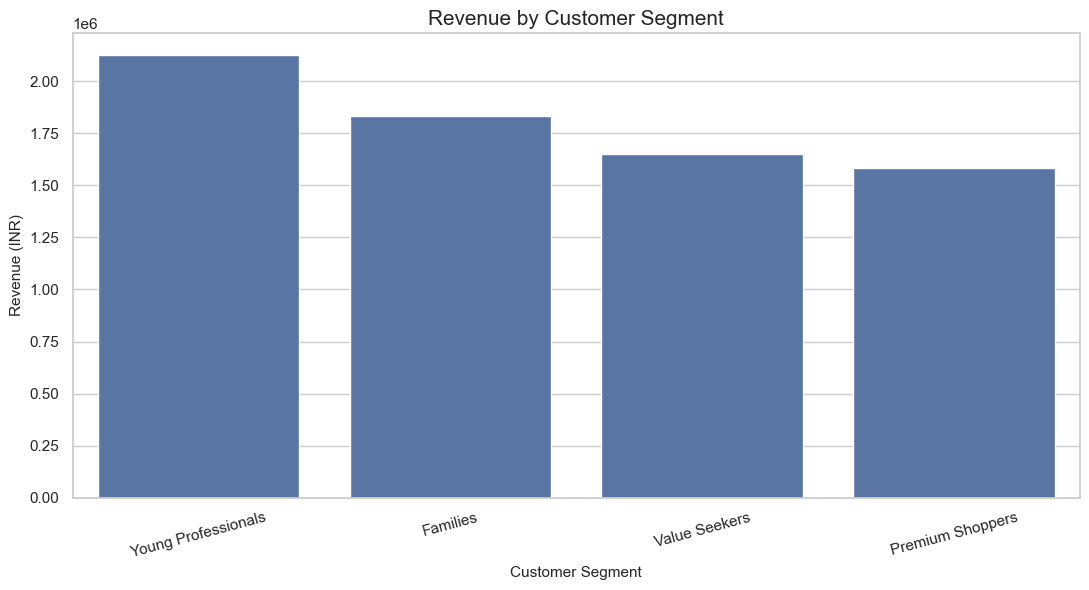

In [29]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_analysis.sort_values(
        "total_revenue", ascending=False
    ),
    x="customer_segment",
    y="total_revenue"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


CORRELATION MATRIX


,impressions,clicks,ad_spend_inr
impressions,1.00,0.50,0.37
clicks,0.50,1.00,0.78
ad_spend_inr,0.37,0.78,1.00


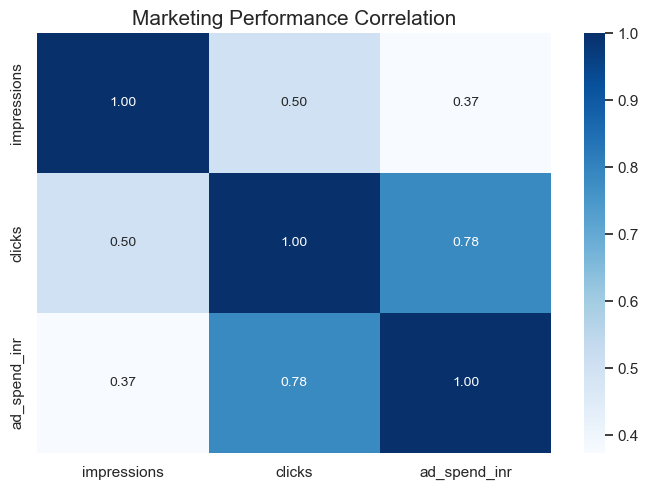

In [30]:

# Correlation Analysis
numeric_data = daily_performance[
    ["impressions", "clicks", "ad_spend_inr"]
]

correlation = numeric_data.corr()

print("CORRELATION MATRIX")
display(correlation.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)
plt.title("Marketing Performance Correlation")
plt.tight_layout()
plt.show()
